# Reactive Cleaning Robots: Statistical Analysis

**Question.** How does the number of robots affect (1) the time until the room is clean, (2) the percentage of clean cells at the end, and (3) the total number of movements?

**Model.** A room of n x m cells, with some percentage of them dirty at random positions. All robots start at cell [1, 1] (index (0, 0) in Mesa). In every step, each robot (in random order) cleans its cell if it is dirty; otherwise it picks one of the 8 neighboring cells at random and moves there. If that cell is outside the room or occupied by another robot, the robot stays where it is. A run ends when the room is clean or the step limit is reached.

**Method.** Every configuration is run with 30 seeds (0 to 29). A seed fixes the dirt layout, so seed *s* gives the same room for every robot count. Comparisons between robot counts are therefore paired. Error bars are 95% confidence intervals of the mean.

**Structure.**
1. Setup
2. Experiment 1: no time limit (time, speedup, movements, congestion)
3. Experiment 2: limited time (clean percentage at the end)
4. Experiment 3: amount of dirt
5. Conclusions


In [ ]:
from experiments.run_experiments import resultsDir, plotAverageMovements, plotAverageSteps, plotCleaningPercentageComparison, plotCleaningPercentageHeatmap, plotDirtComparison, dirtTable, plotFailedMoves, plotSpeedup, plotTimeDistribution, runExperiments


agentConfigurations = [1, 2, 4, 8, 16, 32, 64, 128]
noLimit = 50_000  
stepLimits = [10, 50, 100, 250, 500, 1_000, 2_500, 5_000]
dirtLevels = [0.1, 0.25, 0.5, 0.75, 0.9]

## 2. Experiment 1: no time limit

The step limit of 50,000 is far above the slowest run (about 11,500 steps), so every run cleans the room completely. This experiment answers how the number of robots affects the cleaning time and the number of movements.

In [2]:
summaryNoLimit, _, _ = runExperiments(agentConfigurations, maxSteps= noLimit)

  0%|          | 0/240 [00:00<?, ?it/s]

In [3]:
required = summaryNoLimit[
    ["numAgents", "AverageSteps", "CI95Steps", "AverageCleaningPercentage",
     "AverageMoves", "CI95Moves", "SuccessfulRuns", "Runs"]
].rename(columns={
    "numAgents": "Robots",
    "AverageSteps": "Steps until clean",
    "CI95Steps": "± 95% CI",
    "AverageCleaningPercentage": "Clean cells at end (%)",
    "AverageMoves": "Total movements",
    "CI95Moves": "± 95% CI ",
    "SuccessfulRuns": "Runs finished",
})
required.round(1)

,Robots,Steps until clean,± 95% CI,Clean cells at end (%),Total movements,± 95% CI,Runs finished,Runs
0,1,6580.1,844.7,100.0,5903.0,776.7,30,30
1,2,3411.0,543.1,100.0,6119.2,1012.6,30,30
2,4,1640.8,223.0,100.0,5803.5,817.4,30,30
3,8,846.2,85.4,100.0,5847.4,628.0,30,30
4,16,497.4,39.6,100.0,6453.7,568.3,30,30
5,32,377.0,38.8,100.0,8552.6,1061.6,30,30
6,64,301.4,15.5,100.0,9430.2,734.8,30,30
7,128,284.9,14.3,100.0,8908.2,754.7,30,30


All 240 runs finished, so the clean percentage at the end is 100% for every robot count. With unlimited time, the number of robots only changes *how fast* the room gets clean, not *whether* it does. Experiment 2 looks at the clean percentage under a time limit, where it does differ.

### 2.2 Cleaning time

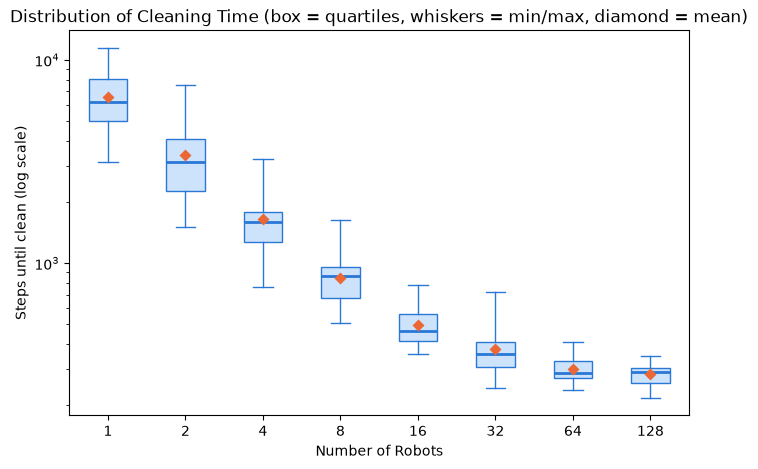

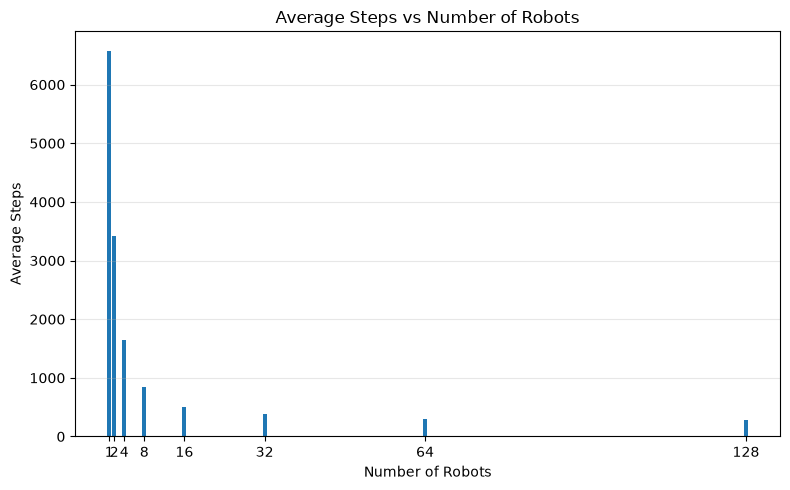

In [4]:
plotTimeDistribution(summaryNoLimit, resultsDir, showPlot=True)
plotAverageSteps(summaryNoLimit, agentConfigurations, resultsDir, showPlot=True)

**Observations**

- The cleaning time falls from about 6,600 steps with 1 robot to about 850 with 8 robots, roughly halving every time the number of robots doubles.
- After that the curve flattens: 16 robots need about 500 steps, 32 about 380, and 64 and 128 robots both need about 280 to 290. Doubling from 64 to 128 robots brings no measurable gain.
- The spread between runs also shrinks. With 1 robot, the same configuration takes between about 3,100 and 11,500 steps depending on the seed; with 128 robots all runs lie within a few hundred steps. A single robot's random walk can miss a dirty cell for a long time, while with many robots it is very likely that one of them passes by soon.

**Why does the time stop falling?** The robots start in one corner and spread out by random walk. A random walk covers distance only in proportion to the square root of the elapsed time, so reaching the far corner of a 20 x 20 room takes a few hundred steps no matter how many robots there are. With 64 or more robots, cleaning is limited by this spreading time, not by the number of robots.

### 2.3 Speedup and efficiency

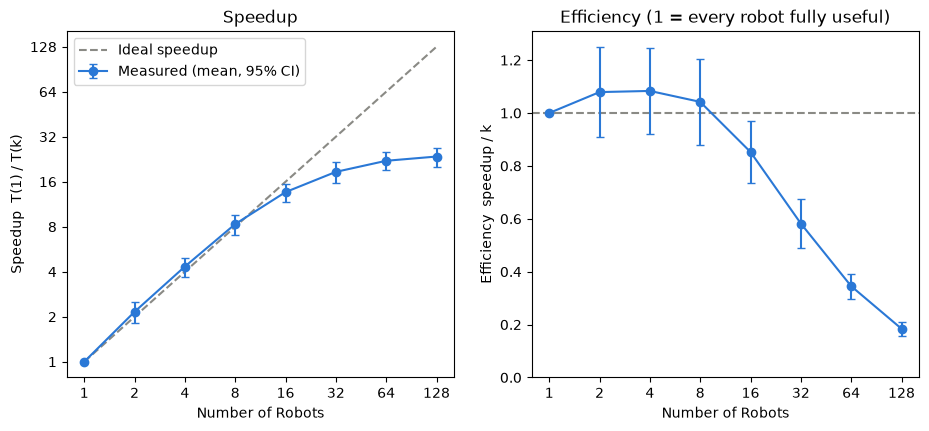

In [5]:
plotSpeedup(summaryNoLimit, agentConfigurations, resultsDir, showPlot=True)

*Speedup* is T(1) / T(k), the time of one robot divided by the time of k robots, computed per seed (same room) and then averaged. *Efficiency* is speedup / k: 1 means every additional robot is fully useful.

**Observations**

- **1 to 8 robots: linear scaling.** Efficiency stays around 1, and all confidence intervals include 1. Doubling the robots halves the time.
- **16 robots and more: diminishing returns.** Efficiency drops to roughly 0.85 at 16, 0.6 at 32, 0.35 at 64 and 0.2 at 128 robots. The maximum speedup is about 24, reached at 64 robots.

The linear phase matches what is known about independent random walks: several walkers on a grid explore it almost k times faster than one, as long as they rarely get in each other's way. The next two sections show why that stops working.

### 2.4 Movements

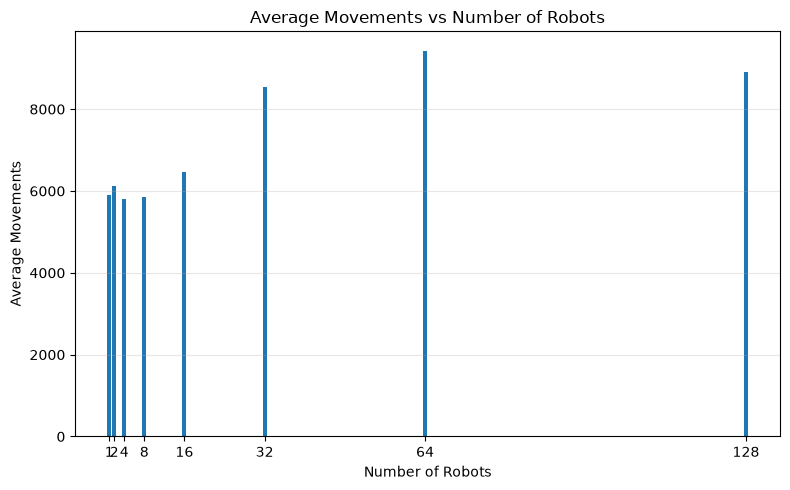

In [6]:
plotAverageMovements(summaryNoLimit, agentConfigurations, resultsDir, showPlot=True)

**Observations**

- **1 to 8 robots: total movements are constant** at about 5,900. The robots do not coordinate, so the total exploration work needed to find every dirty cell stays the same; it is just shared among more robots. Each robot moves about k times less, which is exactly why the time falls as 1/k.
- **16 robots and more: total movements rise** to about 8,500 at 32 and about 9,400 at 64 robots. Robots now often walk over cells that another robot has already cleaned, so part of the movement is wasted. At 128 robots, total movements drop slightly again (about 8,900), because many move attempts fail (next section).

So more robots finish faster, but beyond about 16 robots they also use more total movement to do it.

### 2.5 Failed moves and congestion

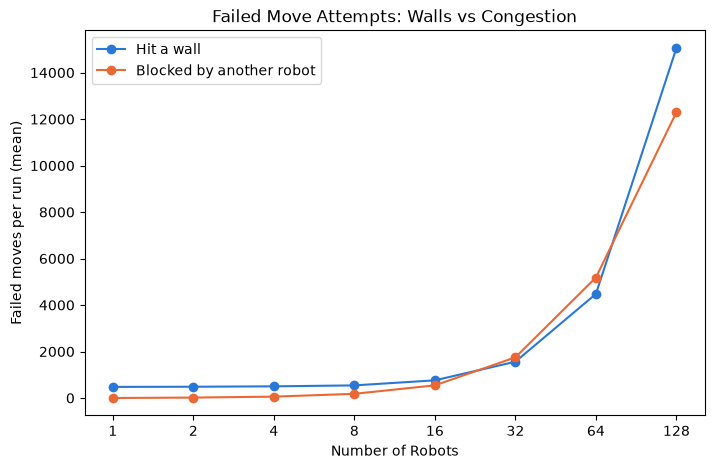

,numAgents,Hit a wall (%),Blocked by robot (%),All failed (%)
0,1,7.5,0.0,7.5
1,2,7.3,0.3,7.6
2,4,7.9,0.9,8.8
3,8,8.3,2.7,11.0
4,16,9.8,7.0,16.8
5,32,13.2,14.7,27.9
6,64,23.5,27.2,50.6
7,128,41.5,33.9,75.4


In [7]:
plotFailedMoves(summaryNoLimit, agentConfigurations, resultsDir, showPlot=True)

attempts = summaryNoLimit["AverageMoves"] + summaryNoLimit["AverageWallBumps"] + summaryNoLimit["AverageBlockedMoves"]
failure = summaryNoLimit[["numAgents"]].assign(
    **{
        "Hit a wall (%)": 100 * summaryNoLimit["AverageWallBumps"] / attempts,
        "Blocked by robot (%)": 100 * summaryNoLimit["AverageBlockedMoves"] / attempts,
        "All failed (%)": 100 * (summaryNoLimit["AverageWallBumps"] + summaryNoLimit["AverageBlockedMoves"]) / attempts,
    }
)
failure.round(1)

The table shows which share of all move attempts failed. Absolute counts grow with the number of robots simply because there are more robots, so the shares are the fairer comparison.

**Observations**

- With few robots, only walls stop a move (around 7% of attempts with 1 robot). Being blocked by another robot almost never happens.
- From 32 robots on, being blocked by another robot becomes as common as hitting a wall. With 128 robots, about three quarters of all move attempts fail.
- Wall bumps also rise with many robots. All robots start in a corner, where 5 of the 8 directions lead out of the room, and a crowded group stays near that corner for longer.

This is the second reason for the diminishing returns: robots physically get in each other's way, especially in the start corner. Together with the spreading time from section 2.2, it explains why 128 robots are no faster than 64.

## 3. Experiment 2: limited time

Here the same 240 configurations are run with several step limits. Because the seeds are the same, the clean percentage after a limit of *L* steps equals the clean percentage at step *L* of the unlimited run. This answers the second required metric in a meaningful way.

Note that half of the room is clean from the start, so the clean percentage begins at 50%.

  0%|          | 0/240 [00:00<?, ?it/s]

  0%|          | 0/240 [00:00<?, ?it/s]

  0%|          | 0/240 [00:00<?, ?it/s]

  0%|          | 0/240 [00:00<?, ?it/s]

  0%|          | 0/240 [00:00<?, ?it/s]

  0%|          | 0/240 [00:00<?, ?it/s]

  0%|          | 0/240 [00:00<?, ?it/s]

  0%|          | 0/240 [00:00<?, ?it/s]

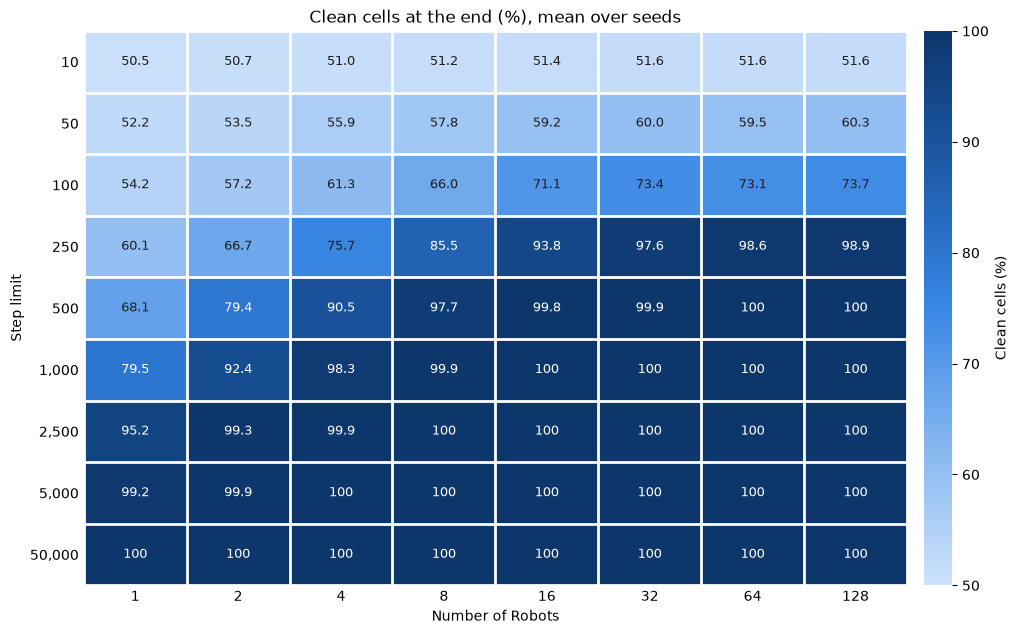

In [8]:
summariesLimit = [summaryNoLimit]  
for limit in stepLimits:
    limited, _, _ = runExperiments(agentConfigurations, maxSteps=limit)
    summariesLimit.append(limited)

plotCleaningPercentageHeatmap(summariesLimit, agentConfigurations, resultsDir, showPlot=True)

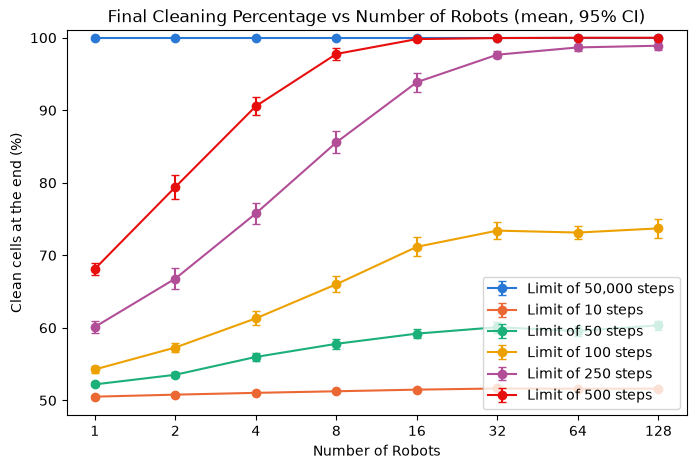

In [9]:
# A few limits as lines
plotCleaningPercentageComparison(summariesLimit, agentConfigurations, resultsDir, showPlot=True)

**Observations**

- **With enough time, the robot count does not matter for the result.** As can be seen in the heatmap, from 5,000 steps on, every configuration is at or above 99%.
- **With little time, more robots clean much more.** After 1,000 steps, 1 robot has cleaned about 80% of the room, 2 robots about 92% and 8 robots almost 100%. After 250 steps, the range is 60% (1 robot) to 99% (128 robots).
- **Very early, extra robots are wasted.** After 10 steps, all configurations are at about 51 to 52%: the robots are still packed in the start corner. After 100 steps, 32, 64 and 128 robots all reach about 73 to 74%. Beyond about 32 robots, extra robots cannot spread out fast enough to help.

Each row of the heatmap shows the same pattern as Experiment 1: going from 1 to 8 robots helps a lot, while beyond 32 robots the values stop improving.

## 4. Experiment 3: amount of dirt

So far, half of the room started dirty. Here the same robot counts are run with 10%, 25%, 50%, 75% and 90% initial dirt, without a time limit. This checks whether the results above depend on the amount of dirt.

  0%|          | 0/240 [00:00<?, ?it/s]

  0%|          | 0/240 [00:00<?, ?it/s]

  0%|          | 0/240 [00:00<?, ?it/s]

  0%|          | 0/240 [00:00<?, ?it/s]

  0%|          | 0/240 [00:00<?, ?it/s]

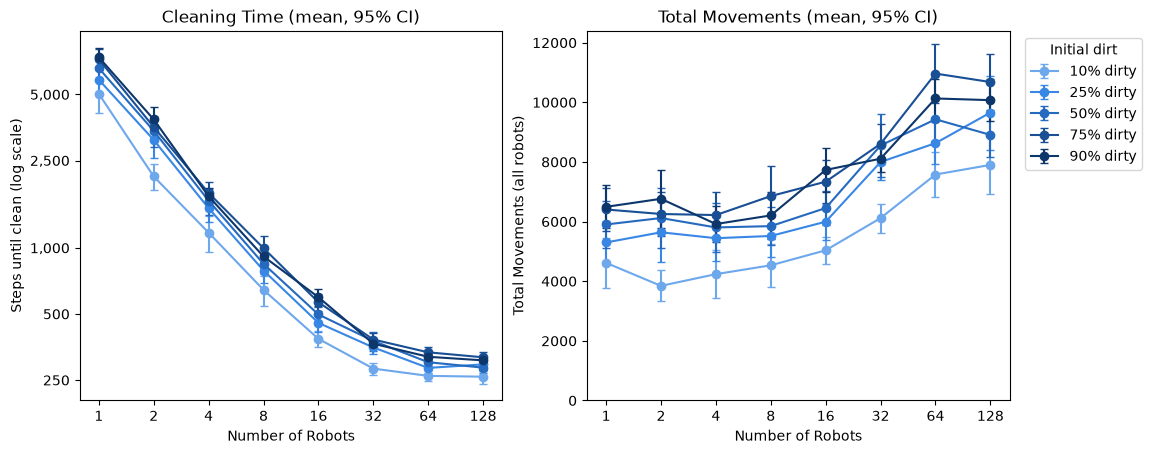

In [10]:
dirtSummaries = []
for dirt in dirtLevels:
    dirtDf, _, _ = runExperiments(
        agentConfigurations, maxSteps=noLimit, dirtyPct=dirt
    )
    dirtSummaries.append(dirtDf)

plotDirtComparison(dirtSummaries, agentConfigurations, resultsDir, showPlot=True)

**Observations**

- **More dirt takes longer, but only moderately.** With one robot, the cleaning time grows from about 5,000 steps at 10% dirt to about 6,600 at 90%: roughly 1.3 times longer for nine times as many dirty cells. Most of the time is spent searching for the last dirty cells, which are spread over the whole room at every dirt level, not on the cleaning actions themselves.
- **The scaling with the number of robots is the same for every dirt level.** The curves run almost parallel: the time halves with each doubling up to about 8 robots and levels off from 32 robots on. The differences between dirt levels shrink with more robots (about 260 vs 330 steps at 128 robots), because then the time is limited by how fast the robots spread from the start corner, not by the amount of dirt.
- **More dirt also means more movement.** Total movements are lowest at 10% dirt for every robot count (about 4,600 with one robot vs about 6,500 at 90%). For every dirt level, total movements rise from about 16 robots on, as robots increasingly walk over cells that others have already cleaned.
- **The movement curves are noisy.** Their confidence intervals overlap a lot, and the 50%, 75% and 90% lines cross each other, so only the overall trends are reliable, not the exact order between neighboring dirt levels.


In [11]:
# Mean steps until clean, per robot count (rows) and dirt level (columns)
dirtTable(dirtSummaries, "AverageSteps")

,10% dirty,25% dirty,50% dirty,75% dirty,90% dirty
numAgents,,,,,
1,5028.9,5831.5,6580.1,7221.6,7378.4
2,2114.3,3100.1,3411.0,3550.3,3845.3
4,1173.1,1516.0,1640.8,1778.6,1717.4
8,643.7,788.8,846.2,997.1,914.0
16,385.3,455.4,497.4,565.6,596.3
32,282.0,352.0,377.0,382.5,366.2
64,261.2,284.0,301.4,334.5,319.2
128,259.0,294.7,284.9,317.5,307.4


In [12]:
# Efficiency (speedup / k): does the scaling depend on the amount of dirt?
dirtTable(dirtSummaries, "Efficiency")

,10% dirty,25% dirty,50% dirty,75% dirty,90% dirty
numAgents,,,,,
1,1.0,1.0,1.0,1.0,1.0
2,1.3,1.1,1.1,1.1,1.1
4,1.3,1.0,1.1,1.1,1.1
8,1.2,1.0,1.0,1.0,1.1
16,0.9,0.8,0.9,0.8,0.8
32,0.6,0.5,0.6,0.6,0.6
64,0.3,0.3,0.3,0.3,0.4
128,0.2,0.2,0.2,0.2,0.2


**Observations**

- **Nine times more dirt takes only about 1.5 times longer.** One robot needs about 4,800 steps at 10% dirt and about 7,500 at 90%, even though the number of dirty cells grows from 40 to 360. The cleaning actions themselves are a small part of this: 320 extra dirty cells cost only 320 extra cleaning steps.
- **The time is dominated by searching, not by cleaning.** Dirty cells are spread randomly over the room, so even at 10% dirt the robots have to visit almost every part of the room to find the last ones. Finding these last few cells by random walk takes most of the time, regardless of how many there are.
- **The scaling behavior does not depend on the amount of dirt.** The efficiency table is almost identical for every dirt level: about 1 up to 8 robots, about 0.6 at 32 and about 0.1 to 0.2 at 128. The lines in the time plot run in parallel.
- **More dirt means more movement**, but again only moderately (about 4,400 vs 6,600 total movements for 1 robot). With many robots, total movements rise for every dirt level, for the same reasons as in section 2.4.

So the conclusions from Experiment 1 hold for any amount of dirt: the number of robots, not the amount of dirt, determines how the cleaning time scales.

## 5. Conclusions

1. **Time until clean.** Up to 8 robots, the cleaning time is inversely proportional to the number of robots (efficiency about 1). From 16 robots on, returns diminish, and 64 or 128 robots both need about 280 to 290 steps. The lower limit comes from how long it takes the robots to spread from the start corner across the room.
2. **Clean percentage at the end.** With unlimited time, every configuration cleans 100% of the room. Under a time limit, more robots clean more, but the benefit saturates at about 32 robots.
3. **Total movements.** Up to 8 robots, the total number of movements is constant: the same work is shared among more robots. With more robots, total movements rise, because robots revisit already clean cells, and with 128 robots most move attempts fail because robots block each other.

**For this room, about 8 robots give the best trade-off**: close to ideal speedup with no extra movement. Up to 32 robots still reduce the time noticeably, but at the cost of extra movement. Beyond that, adding robots brings no further benefit.

4. **Amount of dirt.** More dirt increases the time only moderately (about 1.5 times for nine times as much dirt), because most of the time is spent searching for the last dirty cells. The scaling with the number of robots is the same for every dirt level.

**Limitations.** All results are for one room size (20 x 20), and the robots are purely reactive. Larger rooms would likely move the point of diminishing returns to higher robot counts, and starting the robots at random positions instead of one corner would reduce the congestion effect.